# Métodos del mapa de investigación (versión sencilla)

Este notebook explica, con palabras sencillas, los métodos del mapa de investigación sobre monitoreo de puentes con teléfonos que van dentro de un carro (*drive-by*). Tiene los mismos métodos, en el mismo orden y con la misma numeración que la versión técnica: [research_map_methods.ipynb](research_map_methods.ipynb).

<a id="indice"></a>
## Índice

- [1 Bridge response separation](#bridge-response-separation)
  - [1.1 Road roughness](#road-roughness)
    - [1.1.1 Identical-axle subtraction](#identical-axle-subtraction)
    - [1.1.2 Residual between axles](#residual-between-axles)
  - [1.2 Vehicle dynamics](#vehicle-dynamics)
    - [1.2.1 Contact-point response](#contact-point-response)
- [2 Modal identification](#modal-identification)
  - [2.1 Natural frequencies](#natural-frequencies)
    - [2.1.1 Signal decomposition](#natural-frequencies-signal-decomposition)
      - [2.1.1.1 Cross-correlation](#cross-correlation)
      - [2.1.1.2 FDD (Frequency Domain Decomposition)](#fdd)
    - [2.1.2 Bridge components](#natural-frequencies-bridge-components)
      - [2.1.2.1 Peaks of 1st singular value](#peaks-first-singular-value)
  - [2.2 Mode shapes](#mode-shapes)
    - [2.2.1 Sparse spatial coverage](#sparse-spatial-coverage)
      - [2.2.1.1 Mapping to fixed points](#mapping-fixed-points)
      - [2.2.1.2 Soft imputing](#soft-imputing)
      - [2.2.1.3 FDD on the incomplete matrix](#fdd-incomplete-matrix)
    - [2.2.2 Signal decomposition](#mode-shapes-signal-decomposition)
      - [2.2.2.1 EMD + Hilbert transform](#emd-hilbert)
      - [2.2.2.2 FDD (Frequency Domain Decomposition)](#fdd-mode-shapes)
      - [2.2.2.3 Wavelet transform (SSWT)](#wavelet-sswt)
    - [2.2.3 Bridge components](#mode-shapes-bridge-components)
      - [2.2.3.1 IMF near the exciter frequency](#imf-exciter-frequency)
      - [2.2.3.2 Peaks of 1st singular value](#peaks-first-singular-value-shapes)
      - [2.2.3.3 Band at the known frequency](#band-known-frequency)
    - [2.2.4 Build the shape along the bridge](#build-shape)
      - [2.2.4.1 Rescaling between axles](#rescaling-between-axles)
      - [2.2.4.2 SVD of the completed matrix](#svd-completed-matrix)
      - [2.2.4.3 Singular vectors at peaks](#singular-vectors-peaks)
      - [2.2.4.4 Average of many trips](#average-many-trips)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import Wavelet, ssq_cwt
from ssqueezepy.experimental import scale_to_freq
from PyEMD import EMD
from scipy.signal import hilbert, csd

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def road_profile(length, dx, rng, rms=1.0):
    """Made-up bumpy road: smooth random profile with the given RMS."""
    x = np.arange(0, length, dx)
    k = np.fft.rfftfreq(x.size, dx)
    R = np.fft.rfft(rng.standard_normal(x.size))
    R[1:] /= np.maximum(k[1:], 0.05)
    R[0] = 0
    R[k > 2] = 0
    r = np.fft.irfft(R, x.size)
    return x, rms * r / r.std()


def modal_response(freqs, zeta, fs, n, rng):
    """Vibration of each bridge "note" (modal coordinate), unit RMS, driven by random pushes."""
    w = 2 * np.pi * np.fft.rfftfreq(n, 1 / fs)
    q = []
    for fk in freqs:
        wk = 2 * np.pi * fk
        H = 1 / (wk ** 2 - w ** 2 + 2j * zeta * wk * w)          # one mode: narrow band around f_k
        qk = np.fft.irfft(np.fft.rfft(rng.standard_normal(n)) * H, n)
        q.append(qk / qk.std())
    return np.array(q)


def beam_modes(x_rel, n_modes):
    """Shapes of a simply supported beam, sin(k pi x/L), at relative positions x/L (one column per mode)."""
    return np.column_stack([np.sin((k + 1) * np.pi * x_rel) for k in range(n_modes)])


def mac(a, b):
    """Likeness of two shapes (MAC): 1 = same shape, 0 = unrelated."""
    return np.abs(np.vdot(a, b)) ** 2 / (np.vdot(a, a).real * np.vdot(b, b).real)


def real_shape(u, ref):
    """Turn a complex shape into a real one, scaled to max 1 and with the same sign as ref."""
    u = u * np.exp(-1j * np.angle(u[np.argmax(np.abs(u))]))
    u = u.real / np.max(np.abs(u.real))
    return u if np.dot(u, ref) >= 0 else -u


# Synthetic example (same as the technical notebook): a car crosses a 100 m bridge at 20 m/s
L = 100.0                               # bridge length, m
v = 20.0                                # car speed, m/s
f_mode = 1.3                            # bridge "note" (mode 2 frequency), Hz
fs = 100.0                              # sampling rate, Hz

t = np.arange(0, L / v, 1 / fs)         # time, s
pos = v * t                             # car position on the bridge, m
shape_true = np.sin(2 * np.pi * pos / L)  # how the bridge bends: up on one half, down on the other
x = np.abs(shape_true) * np.cos(2 * np.pi * f_mode * t) + 0.1 * rng.standard_normal(t.size)

# Wavelet maps: CWT (Wx) and synchrosqueezed SSWT (Tx), analytic Morlet wavelet
wavelet = Wavelet(("morlet", {"mu": 3}))
Tx, Wx, freqs_ssq, scales = ssq_cwt(x, wavelet, fs=fs, nv=32, padtype="zero")
freqs_cwt = scale_to_freq(scales, wavelet, N=2 ** 14, fs=fs)

---

<a id="bridge-response-separation"></a>
## 1 Bridge response separation

---

<a id="road-roughness"></a>
### 1.1 Road roughness

<a id="identical-axle-subtraction"></a>
#### 1.1.1 Identical-axle subtraction

*Versión técnica: [research_map_methods.ipynb, sección 1.1.1](research_map_methods.ipynb#identical-axle-subtraction)*

**Qué es**

- Es restar lo que miden dos ruedas iguales para borrar los baches del camino.
- Analogía: dos personas iguales caminan por el mismo camino de piedras. Las dos tropiezan igual en las mismas piedras. Si restas lo que sintió una de lo que sintió la otra, las piedras se borran.

**Para qué sirve**

- Los baches sacuden mucho al carro y tapan la vibración del puente, que es pequeña.
- Analogía: es como querer oír a alguien que susurra mientras pasa un camión.

**Cómo funciona**

1. Dos ruedas iguales pasan por los mismos baches.
2. Cada una siente los baches de la misma forma cuando pasa por ellos.
3. Se compara lo que sintió cada rueda en el mismo punto del camino y se resta. Los baches se borran y queda lo que viene del puente.

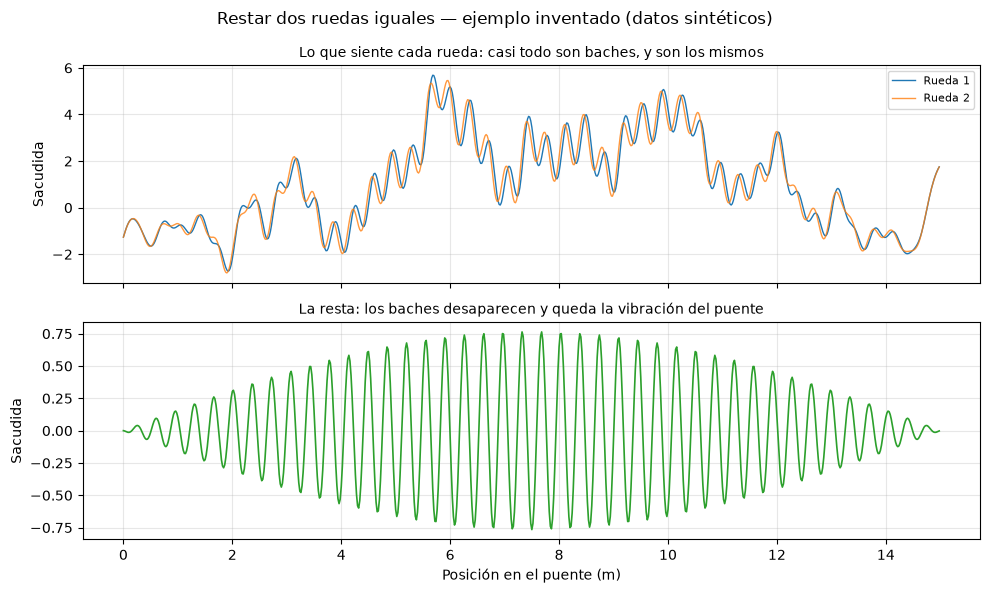

In [2]:
# Two equal wheels over the same bumps, and their subtraction (made-up example)
rng_ax = np.random.default_rng(SEED + 10)
x_ax = np.arange(0, 15, 0.02)                       # position on the bridge, m
_, bumps = road_profile(60.0, 0.02, rng_ax)
bumps = 3.0 * np.convolve(bumps, np.ones(5) / 5, mode="same")[1000:1000 + x_ax.size]   # same bumps for both
shape_ax = np.sin(np.pi * x_ax / 15)
bridge1 = shape_ax * np.cos(2 * np.pi * 5.65 * x_ax / 2.0)          # bridge felt by wheel 1
bridge2 = shape_ax * np.cos(2 * np.pi * 5.65 * (x_ax + 5.0) / 2.0)  # wheel 2 passes 2.5 s later
wheel1, wheel2 = bumps + bridge1, bumps + bridge2

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(x_ax, wheel1, color="C0", lw=1, label="Rueda 1")
axes[0].plot(x_ax, wheel2, color="C1", lw=1, alpha=0.8, label="Rueda 2")
axes[0].set_title("Lo que siente cada rueda: casi todo son baches, y son los mismos", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(x_ax, wheel2 - wheel1, color="C2", lw=1.2)
axes[1].set_title("La resta: los baches desaparecen y queda la vibración del puente", fontsize=10)
for ax in axes:
    ax.set_ylabel("Sacudida")
axes[-1].set_xlabel("Posición en el puente (m)")
fig.suptitle("Restar dos ruedas iguales — ejemplo inventado (datos sintéticos)")
fig.tight_layout()
plt.show()

**Figura 1.** Lo que sienten dos ruedas iguales en un puente inventado (ilustrativo, datos sintéticos): arriba, las dos curvas casi se tapan entre sí porque los baches son los mismos y mucho más grandes que el puente. Abajo, al restarlas, los baches se borran y queda una vibración ordenada que crece hacia el centro del puente.

**Ventajas**

- No hay que conocer el camino.

**Desventajas**

- Las ruedas tienen que ser idénticas e ir por el mismo lugar.
- Solo se probó en simulación.

**Artículos:** Malekjafarian y OBrien (2017).

**Entradas y salidas**

- **Entrada:** lo que miden dos ruedas iguales.
- **Salida:** una vibración sin los baches.
- **Qué se obtiene o interpreta:** la vibración del puente se ve más clara.

[↑ Volver al índice](#indice)

<a id="residual-between-axles"></a>
#### 1.1.2 Residual between axles

*Versión técnica: [research_map_methods.ipynb, sección 1.1.2](research_map_methods.ipynb#residual-between-axles)*

**Qué es**

- Es restar lo que mide la rueda trasera ahora menos lo que midió la delantera un momento antes, cuando estaba en el mismo bache.
- Analogía: la rueda de atrás pisa el mismo bache que la de adelante, un poquito después. Si comparas los dos momentos, el bache se borra y solo queda lo que cambió el puente.

**Para qué sirve**

- Para borrar los baches con un solo carro, aunque sus dos ruedas no sean iguales.

**Cómo funciona**

1. Se sabe cuánto tarda la rueda de atrás en llegar a donde estaba la de adelante: la distancia entre ruedas dividida entre la velocidad. Con 3 m y 25 m/s, son 0.12 s.
2. Se compara la rueda de atrás con la de adelante 0.12 s antes.
3. La resta borra el bache. Lo que queda es cuánto se movió el puente en ese momento.

Analogía: es como dos fotos del mismo lugar tomadas con un instante de diferencia. Lo que no cambió se borra al compararlas; lo que se movió, queda.

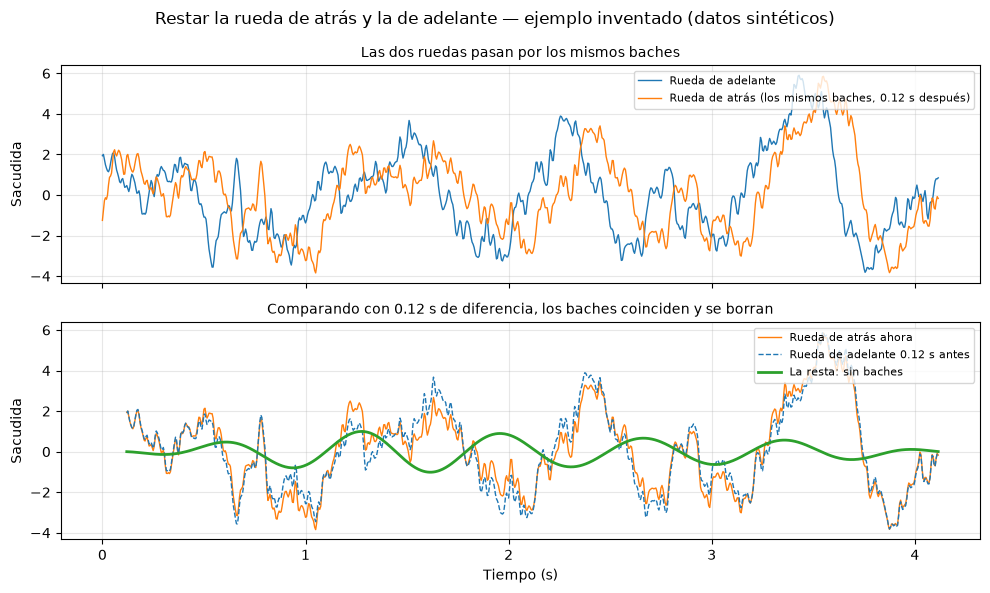

In [3]:
# Front and rear wheel over the same bumps, 0.12 s apart, and the subtraction (made-up example)
rng_res = np.random.default_rng(SEED + 11)
fs_r, v_r, d_r = 200.0, 25.0, 3.0
k_dt = int(round(d_r / v_r * fs_r))              # 0.12 s in samples
t_r = np.arange(0, 103 / v_r, 1 / fs_r)
x_front = v_r * t_r
xp_r, prof_r = road_profile(200.0, 0.01, rng_res, rms=2.0)
q_r = np.cos(2 * np.pi * 1.44 * t_r) * (1 + 0.3 * np.sin(2 * np.pi * 0.3 * t_r))
def on_bridge(x):
    return np.where((x >= 0) & (x <= 100), np.sin(np.pi * np.clip(x, 0, 100) / 100), 0.0)
front = np.interp(x_front + 50, xp_r, prof_r) + on_bridge(x_front) * q_r
rear = np.interp(x_front - d_r + 50, xp_r, prof_r) + on_bridge(x_front - d_r) * q_r
ok = np.arange(k_dt, t_r.size)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(t_r, front, color="C0", lw=1, label="Rueda de adelante")
axes[0].plot(t_r, rear, color="C1", lw=1, label="Rueda de atrás (los mismos baches, 0.12 s después)")
axes[0].set_title("Las dos ruedas pasan por los mismos baches", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(t_r[ok], rear[ok], color="C1", lw=1, label="Rueda de atrás ahora")
axes[1].plot(t_r[ok], front[ok - k_dt], "--", color="C0", lw=1, label="Rueda de adelante 0.12 s antes")
axes[1].plot(t_r[ok], rear[ok] - front[ok - k_dt], color="C2", lw=2, label="La resta: sin baches")
axes[1].set_title("Comparando con 0.12 s de diferencia, los baches coinciden y se borran", fontsize=10)
axes[1].legend(loc="upper right", fontsize=8)
for ax in axes:
    ax.set_ylabel("Sacudida")
axes[-1].set_xlabel("Tiempo (s)")
fig.suptitle("Restar la rueda de atrás y la de adelante — ejemplo inventado (datos sintéticos)")
fig.tight_layout()
plt.show()

**Figura 2.** Las dos ruedas de un carro inventado sobre los mismos baches (ilustrativo, datos sintéticos): arriba, la rueda de atrás repite los baches un poco después. Abajo, al comparar la rueda de atrás con la de adelante 0.12 s antes, los baches coinciden; la resta (verde) es una curva suave que viene solo del puente.

**Ventajas**

- Sirve con un solo carro.

**Desventajas**

- Hay que saber la distancia entre ruedas y la velocidad.

**Artículos:** Talebi-Kalaleh et al. (2025).

**Entradas y salidas**

- **Entrada:** lo que miden las dos ruedas.
- **Salida:** la parte que cambió por el puente.
- **Qué se obtiene o interpreta:** con eso se estima cuánto vibra el puente.

[↑ Volver al índice](#indice)

---

<a id="vehicle-dynamics"></a>
### 1.2 Vehicle dynamics

<a id="contact-point-response"></a>
#### 1.2.1 Contact-point response

*Versión técnica: [research_map_methods.ipynb, sección 1.2.1](research_map_methods.ipynb#contact-point-response)*

**Qué es**

- Es pasar lo que mide el teléfono dentro del carro a lo que pasa donde la llanta toca el piso.
- Analogía: el asiento de un carro se mueve suave porque la suspensión amortigua. Si conoces la suspensión, puedes calcular cómo se movió la llanta.

**Para qué sirve**

- El carro tiene su propio rebote, que se mezcla con la vibración del puente.
- Al pasar la señal a la llanta, ese rebote del carro desaparece.
- Analogía: es como quitarle el eco a una grabación para oír la voz original.

**Cómo funciona**

1. El teléfono mide cuánto sube y baja el carro y cuánto se inclina hacia adelante y hacia atrás.
2. Con el peso, las medidas y la suspensión del carro, se calcula qué movimiento de las llantas produjo eso.
3. Se obtiene cómo se movió el piso bajo cada llanta: baches más puente, sin el rebote del carro.

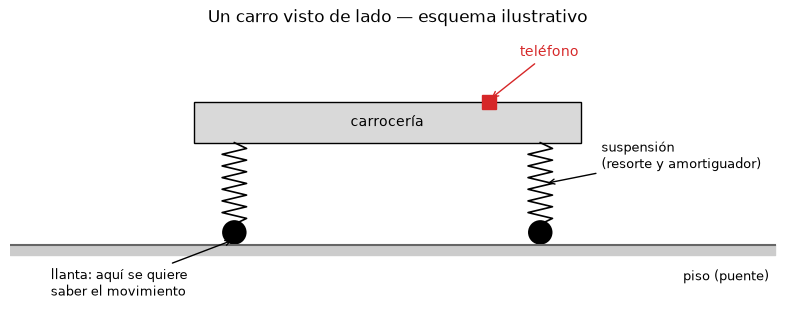

In [4]:
# Simple sketch of the car: body, phone, suspensions and wheels
from matplotlib.patches import Rectangle, Circle

def spring(ax, x, y0, y1, n=6, w=0.12):
    ys = np.linspace(y0, y1, 2 * n + 3)
    xs = np.r_[x, x + w * np.tile([1, -1], n + 1)[:2 * n + 1], x]
    ax.plot(xs, ys, color="k", lw=1.2)

fig, ax = plt.subplots(figsize=(10, 4))
ax.add_patch(Rectangle((-2.2, 1.0), 3.8, 0.4, fc="0.85", ec="k"))
ax.text(-0.3, 1.2, "carrocería", ha="center", va="center", fontsize=10)
ax.plot(0.7, 1.4, "s", color="C3", ms=10)
ax.annotate("teléfono", (0.7, 1.42), xytext=(1.0, 1.85), color="C3", fontsize=10,
            arrowprops=dict(arrowstyle="->", color="C3"))
for xa in (-1.8, 1.2):
    spring(ax, xa, 0.2, 1.0)
    ax.add_patch(Circle((xa, 0.12), 0.12, fc="k"))
ax.annotate("suspensión\n(resorte y amortiguador)", (1.25, 0.6), xytext=(1.8, 0.75), fontsize=9,
            arrowprops=dict(arrowstyle="->"))
ax.annotate("llanta: aquí se quiere\nsaber el movimiento", (-1.8, 0.05), xytext=(-3.6, -0.5), fontsize=9,
            arrowprops=dict(arrowstyle="->"))
ax.plot([-4, 3.5], [0, 0], color="0.4")
ax.fill_between([-4, 3.5], -0.1, 0, color="0.8")
ax.text(2.6, -0.35, "piso (puente)", fontsize=9)
ax.set_xlim(-4, 3.6)
ax.set_ylim(-0.7, 2.1)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Un carro visto de lado — esquema ilustrativo")
plt.show()

**Figura 3.** Esquema de un carro visto de lado (ilustrativo): el teléfono va en la carrocería, que se apoya en dos suspensiones. Lo que se quiere saber es cómo se movió el piso bajo cada llanta.

**Ventajas**

- Quita el efecto del carro.

**Desventajas**

- Hay que conocer la suspensión, el peso y las medidas de cada carro.

**Artículos:** Talebi-Kalaleh et al. (2025).

**Entradas y salidas**

- **Entrada:** lo que mide el teléfono y las medidas del carro.
- **Salida:** cómo se movieron las llantas.
- **Qué se obtiene o interpreta:** una señal que ya no tiene el efecto del carro.

[↑ Volver al índice](#indice)

---

<a id="modal-identification"></a>
## 2 Modal identification

---

<a id="natural-frequencies"></a>
### 2.1 Natural frequencies

<a id="natural-frequencies-signal-decomposition"></a>
#### 2.1.1 Signal decomposition

<a id="cross-correlation"></a>
##### 2.1.1.1 Cross-correlation

*Versión técnica: [research_map_methods.ipynb, sección 2.1.1.1](research_map_methods.ipynb#cross-correlation)*

*No aparece en el mapa; se explica aquí porque es el primer paso del FDD.*

**Qué es**

- Es una forma de medir qué tanto se parecen dos vibraciones, aunque una vaya un poco atrasada.
- Analogía: dos personas cantan la misma canción, pero una empezó un segundo después. Si "corres" a una un segundo, las dos coinciden.

**Para qué sirve**

- Para saber qué puntos del puente se mueven juntos.
- El ruido de cada punto es distinto y se cancela. Lo que se mueve igual en todos los puntos queda: eso son los modos del puente.
- Analogía: en un salón lleno, cada persona habla de algo distinto y solo se oye un murmullo. Pero si todos cantan la misma canción, la canción se oye por encima del murmullo.

**Cómo funciona**

1. Se toma una vibración y se mueve un poquito en el tiempo.
2. Se compara con la otra y se anota qué tanto coinciden.
3. Se repite para muchos desplazamientos. Donde más coinciden, ese es el atraso.
4. Se hace lo mismo para todos los pares de puntos. Sale una tabla de "qué tanto se parecen" todos los puntos entre sí.

Analogía: es como deslizar un dibujo en papel transparente sobre otro hasta que las líneas quedan una encima de la otra.

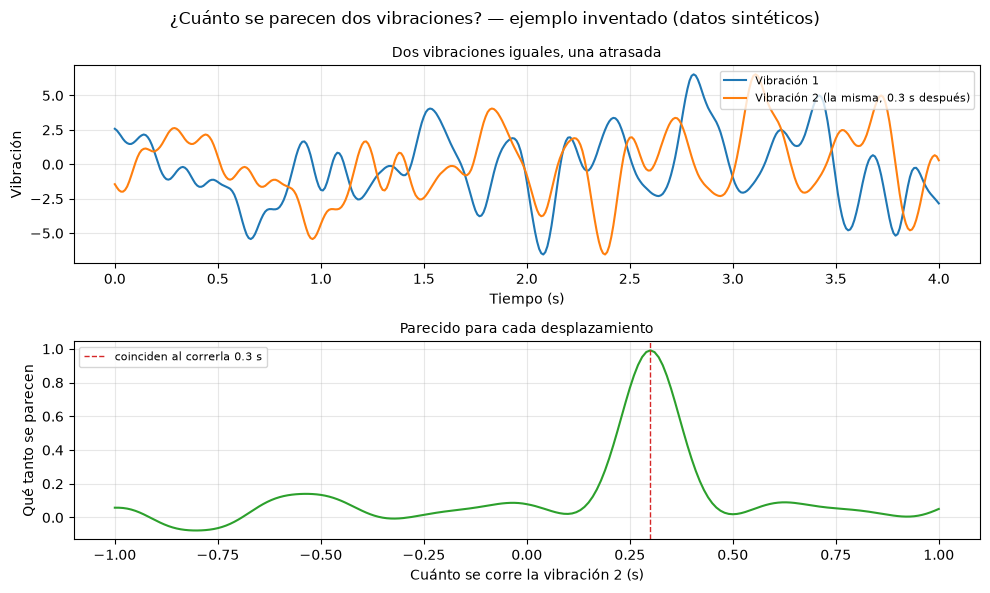

In [5]:
# Two equal vibrations, the second one 0.3 s late, and how much they match for each shift
rng_xc = np.random.default_rng(SEED)    # own generator: keeps the other sections unchanged
fs_c = 100.0                            # samples per second
d = int(0.3 * fs_c)                     # delay: 0.3 s
n_c = int(20 * fs_c)                    # 20 s of vibration
kernel = np.exp(-0.5 * (np.arange(-15, 16) / 5) ** 2)
raw = np.convolve(rng_xc.standard_normal(n_c + d), kernel, mode="same")
x1_c, x2_c = raw[d:], raw[:n_c]         # second vibration = first one, 0.3 s late
t_c = np.arange(n_c) / fs_c

lags = np.arange(-int(fs_c), int(fs_c) + 1)          # shifts from -1 s to +1 s
match = np.array([np.dot(x1_c[:n_c - k], x2_c[k:]) if k >= 0 else np.dot(x1_c[-k:], x2_c[:n_c + k])
                  for k in lags]) / n_c / np.sqrt(np.mean(x1_c ** 2) * np.mean(x2_c ** 2))
shift = lags / fs_c
best = shift[np.argmax(match)]

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
show = t_c <= 4
axes[0].plot(t_c[show], x1_c[show], color="C0", label="Vibración 1")
axes[0].plot(t_c[show], x2_c[show], color="C1", label="Vibración 2 (la misma, 0.3 s después)")
axes[0].set_xlabel("Tiempo (s)")
axes[0].set_ylabel("Vibración")
axes[0].set_title("Dos vibraciones iguales, una atrasada", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(shift, match, color="C2")
axes[1].axvline(best, color="C3", ls="--", lw=1, label=f"coinciden al correrla {best:.1f} s")
axes[1].set_xlabel("Cuánto se corre la vibración 2 (s)")
axes[1].set_ylabel("Qué tanto se parecen")
axes[1].set_title("Parecido para cada desplazamiento", fontsize=10)
axes[1].legend(loc="upper left", fontsize=8)
fig.suptitle("¿Cuánto se parecen dos vibraciones? — ejemplo inventado (datos sintéticos)")
fig.tight_layout()
plt.show()

**Figura 4.** Dos vibraciones inventadas, una atrasada 0.3 s (ilustrativo): abajo se ve que casi no se parecen, salvo cuando la segunda se corre justo 0.3 s; ahí aparece un pico y coinciden casi por completo.

**En el puente**

- El puente vibra en unas pocas "notas". Una nota es una frecuencia: cuántas veces por segundo va y viene el puente.
- Cada nota, con su forma de moverse, se llama **modo**.
- Dos puntos del puente vibran distinto, pero los dos están hechos de las mismas notas, mezcladas en distinta cantidad.
- Analogía: son como dos jugos hechos con las mismas frutas, pero en distinta proporción.

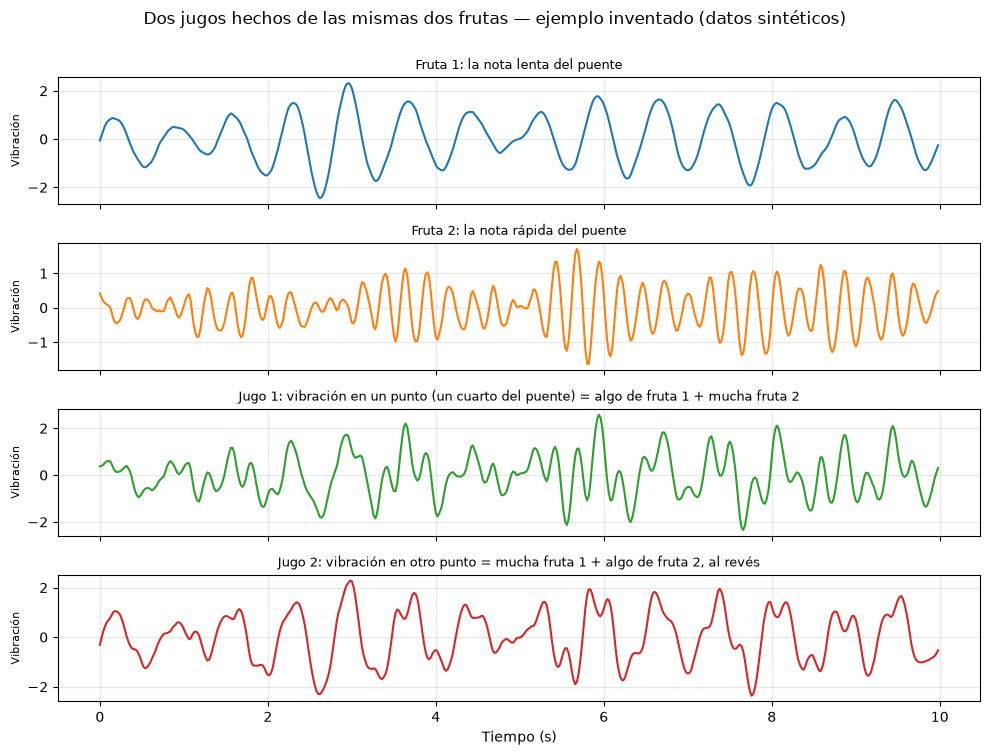

In [6]:
# Two "fruits" (the two bridge notes) and two "juices" (the vibration at two points)
rng_2m = np.random.default_rng(SEED + 1)
fs_2m = 50.0
t_2m = np.arange(0, 10, 1 / fs_2m)
fruits = modal_response([1.44, 3.68], 0.02, fs_2m, t_2m.size, rng_2m) * np.array([[1.0], [0.6]])
weights = beam_modes(np.array([0.25, 0.6]), 2)       # how much of each note at each point
juices = weights @ fruits

rows = [(fruits[0], "C0", "Fruta 1: la nota lenta del puente"),
        (fruits[1], "C1", "Fruta 2: la nota rápida del puente"),
        (juices[0], "C2", "Jugo 1: vibración en un punto (un cuarto del puente) = algo de fruta 1 + mucha fruta 2"),
        (juices[1], "C3", "Jugo 2: vibración en otro punto = mucha fruta 1 + algo de fruta 2, al revés")]
fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
for ax, (y, color, title) in zip(axes, rows):
    ax.plot(t_2m, y, color=color)
    ax.set_title(title, fontsize=9)
    ax.set_ylabel("Vibración", fontsize=8)
axes[-1].set_xlabel("Tiempo (s)")
fig.suptitle("Dos jugos hechos de las mismas dos frutas — ejemplo inventado (datos sintéticos)", y=1.0)
fig.tight_layout()
plt.show()

**Figura 5.** Dos puntos de un puente inventado (ilustrativo, datos sintéticos): las dos vibraciones de abajo se ven distintas, pero las dos se arman con las mismas dos notas de arriba, en distinta cantidad. En el segundo punto la nota rápida entra "al revés": cuando en un punto sube, en el otro baja.

**Ventajas**

- Quita el ruido.
- No hay que saber qué hizo vibrar el puente.

**Desventajas**

- Necesita mediciones largas.
- Con datos faltantes, la comparación es menos confiable.

**Artículos:** Talebi-Kalaleh et al. (2025).

**Entradas y salidas**

- **Entrada:** la vibración de varios puntos del puente, medida al mismo tiempo.
- **Salida:** una tabla de parecido entre todos los pares de puntos.
- **Qué se obtiene o interpreta:** qué puntos se mueven juntos. Es el primer paso del FDD.

[↑ Volver al índice](#indice)

<a id="fdd"></a>
##### 2.1.1.2 FDD (Frequency Domain Decomposition)

*Versión técnica: [research_map_methods.ipynb, sección 2.1.1.2](research_map_methods.ipynb#fdd)*

**Qué es**

- Es un método que encuentra las notas del puente y la forma en que se mueve con cada una, usando solo lo que se midió.
- La forma modal es el dibujo de cómo se deforma el puente cuando vibra en una de sus notas.
- Analogía: es como escuchar una orquesta desde varios asientos. Comparando lo que se oye en cada asiento, se sabe qué instrumentos hay y dónde suena más fuerte cada uno.

**Para qué sirve**

- Para sacar las frecuencias y las formas modales sin saber qué hizo vibrar el puente.
- Analogía: es como reconocer las notas de una campana solo por cómo suena, sin ver quién la golpeó.

**Cómo funciona**

1. Se compara la vibración de todos los puntos entre sí (correlación cruzada, [2.1.1.1](#cross-correlation)).
2. Se pasa a "notas" (frecuencias).
3. En cada nota se separa la parte que todos los puntos comparten. Para eso se usa la SVD, que se explica en [2.2.4.2](#svd-completed-matrix).
4. Donde esa parte compartida es muy fuerte, hay una nota del puente.
5. Cómo se reparte esa parte entre los puntos es la forma modal.

Analogía: en un coro, cuando todos cantan la misma nota, esa nota se oye mucho más fuerte que las demás. Y si se camina entre los cantantes, se nota quién la canta más fuerte.

**En el puente**

- Se usó con datos de muchos carros, aunque faltaba el 80 % de los datos.
- Los huecos se llenaron con ceros.

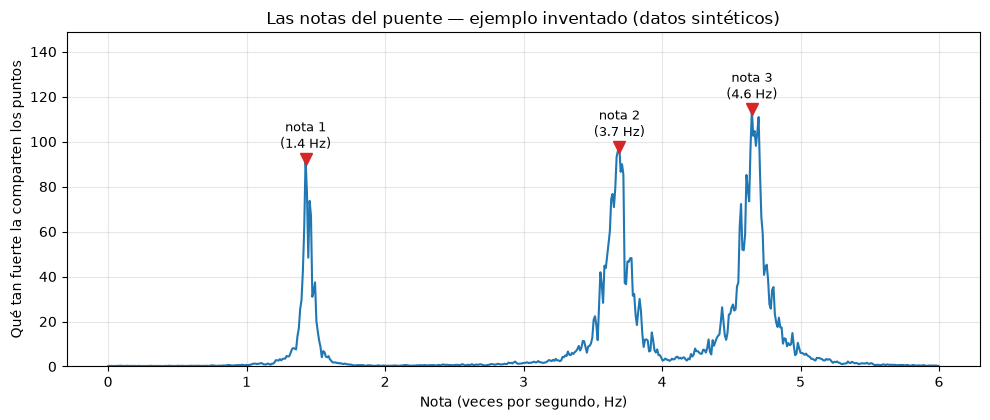

In [7]:
# Example: 17 points of a made-up bridge with 3 notes, shaken at random
rng_beam = np.random.default_rng(SEED + 2)
fs_beam = 20.0                                   # samples per second
n_beam = int(1200 * fs_beam)                     # 20 minutes of vibration
notes = np.array([1.44, 3.68, 4.66])             # example bridge notes, Hz
x_rel = np.arange(1, 18) / 18                    # 17 points along the bridge
shapes_true = beam_modes(x_rel, 3)               # true shapes of the 3 notes
q_beam = modal_response(notes, 0.02, fs_beam, n_beam, rng_beam) * np.array([[1.0], [1.6], [1.8]])
x_beam = shapes_true @ q_beam + 0.1 * rng_beam.standard_normal((17, n_beam))

f_fdd, G = csd(x_beam[:, None, :], x_beam[None, :, :], fs=fs_beam, nperseg=2048)   # compare all pairs, by note
U_fdd, s_fdd, _ = np.linalg.svd(np.moveaxis(G, -1, 0))                            # shared part at each note
peaks = [np.flatnonzero(np.abs(f_fdd - fn) <= 0.15)[np.argmax(s_fdd[np.abs(f_fdd - fn) <= 0.15, 0])]
         for fn in notes]

fig, ax = plt.subplots(figsize=(10, 4.3))
keep = f_fdd <= 6
ax.plot(f_fdd[keep], s_fdd[keep, 0], color="C0")
for k, i in enumerate(peaks):
    ax.plot(f_fdd[i], s_fdd[i, 0], "v", color="C3", ms=9)
    ax.annotate(f"nota {k + 1}\n({f_fdd[i]:.1f} Hz)", (f_fdd[i], s_fdd[i, 0]), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9)
ax.set_ylim(0, s_fdd[keep, 0].max() * 1.3)
ax.set_xlabel("Nota (veces por segundo, Hz)")
ax.set_ylabel("Qué tan fuerte la comparten los puntos")
ax.set_title("Las notas del puente — ejemplo inventado (datos sintéticos)")
fig.tight_layout()
plt.show()

**Figura 6.** La curva del FDD para un puente inventado con 17 puntos (ilustrativo, datos sintéticos): tiene tres picos, uno por cada nota del puente. Entre los picos la curva casi no sube: ahí no hay ninguna nota.

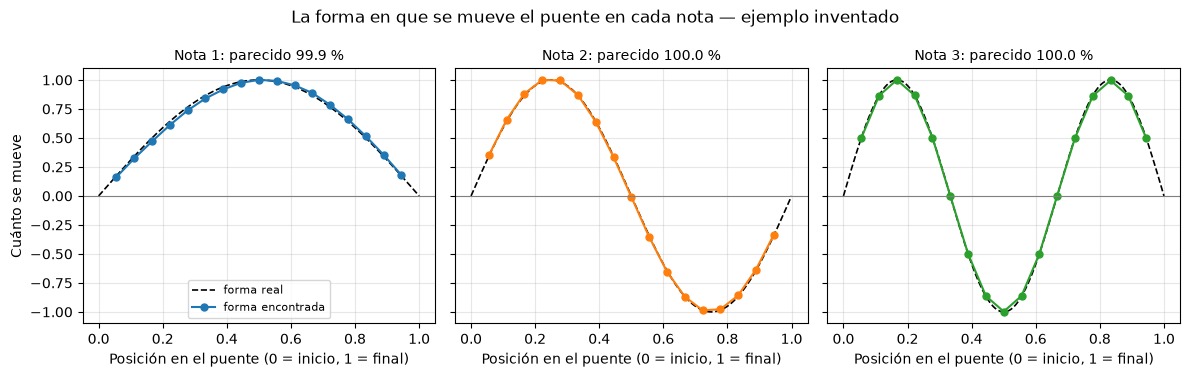

In [8]:
# The shape found at each peak next to the real shape
x_fine = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for k, (ax, i) in enumerate(zip(axes, peaks)):
    found = real_shape(U_fdd[i, :, 0], shapes_true[:, k])
    ax.plot(x_fine, np.sin((k + 1) * np.pi * x_fine), "k--", lw=1.2, label="forma real")
    ax.plot(x_rel, found, "o-", color=f"C{k}", ms=5, label="forma encontrada")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(f"Nota {k + 1}: parecido {100 * mac(shapes_true[:, k], U_fdd[i, :, 0]):.1f} %", fontsize=10)
    ax.set_xlabel("Posición en el puente (0 = inicio, 1 = final)")
axes[0].set_ylabel("Cuánto se mueve")
axes[0].legend(loc="lower center", fontsize=8)
fig.suptitle("La forma en que se mueve el puente en cada nota — ejemplo inventado")
fig.tight_layout()
plt.show()

**Figura 7.** La forma encontrada en cada pico junto a la forma real (ilustrativo, datos sintéticos): en las tres notas los puntos caen sobre la línea punteada. Con la nota 1 todo el puente sube a la vez; con la 2, una mitad sube y la otra baja; con la 3, el puente se divide en tres partes.

**Ventajas**

- No hay que medir lo que excita al puente.
- Es rápido.
- Separa notas cercanas.
- Da frecuencias y formas a la vez.

**Desventajas**

- Supone que la excitación es pareja en todas las notas.
- No da el amortiguamiento, es decir, qué tan rápido se apaga la vibración.
- Necesita medir varios puntos a la vez.

**Pregunta abierta**

> ¿Por qué funciona aunque falten tantos datos?

**Artículos:** Talebi-Kalaleh et al. (2025).

**Entradas y salidas**

- **Entrada:** las vibraciones de varios puntos del puente, medidas al mismo tiempo.
- **Salida:** una curva con picos.
- **Qué se obtiene o interpreta:** cada pico es una nota del puente, y en cada pico sale la forma en que se mueve.

[↑ Volver al índice](#indice)

<a id="natural-frequencies-bridge-components"></a>
#### 2.1.2 Bridge components

<a id="peaks-first-singular-value"></a>
##### 2.1.2.1 Peaks of 1st singular value

Se explica dentro del FDD, [2.1.1.2](#fdd), paso 4.

---

<a id="mode-shapes"></a>
### 2.2 Mode shapes

<a id="sparse-spatial-coverage"></a>
#### 2.2.1 Sparse spatial coverage

<a id="mapping-fixed-points"></a>
##### 2.2.1.1 Mapping to fixed points

*Versión técnica: [research_map_methods.ipynb, sección 2.2.1.1](research_map_methods.ipynb#mapping-fixed-points)*

**Qué es**

- Es pasar lo que miden los carros, que se mueven, a puntos fijos del puente.
- Analogía: como repartir lo que mide un termómetro que se mueve entre las dos estaciones fijas más cercanas, según qué tan cerca está de cada una.

**Para qué sirve**

- Cada carro mide en un lugar distinto en cada momento.
- Para sacar la forma del puente hace falta saber qué pasa siempre en los mismos lugares.

**Cómo funciona**

1. Se marcan puntos fijos a lo largo del puente.
2. Lo que mide un carro se reparte entre los dos puntos fijos que tiene a los lados. El más cercano recibe más.
3. Un punto fijo solo vale si tiene al menos dos mediciones cerca. Si no, queda como hueco.

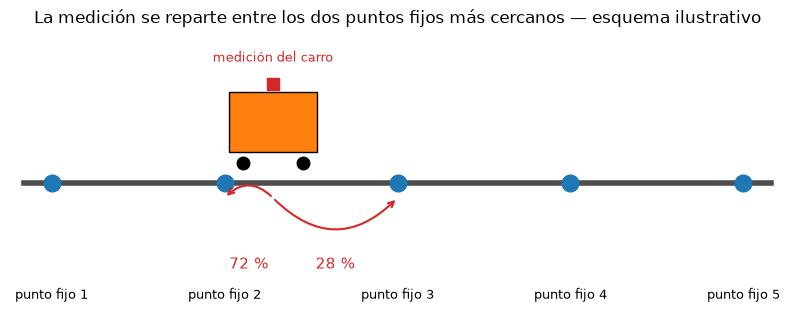

In [9]:
# A bridge with fixed points and a car between two of them
from matplotlib.patches import Rectangle, Circle
pts = np.arange(5) * 6.25                       # fixed points, m
x_car = 8.0                                     # where the car measures, m
w_left = 1 - (x_car - pts[1]) / 6.25            # share for the closest point on the left

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot([-1, 26], [0, 0], color="0.3", lw=4)
for j, p in enumerate(pts):
    ax.plot(p, 0, "o", color="C0", ms=12, zorder=3)
    ax.text(p, -1.15, f"punto fijo {j + 1}", ha="center", fontsize=9)
ax.add_patch(Rectangle((x_car - 1.6, 0.3), 3.2, 0.6, fc="C1", ec="k"))
ax.plot([x_car - 1.1, x_car + 1.1], [0.2, 0.2], "o", color="k", ms=9)       # wheels
ax.plot(x_car, 0.98, "s", color="C3", ms=8)
ax.text(x_car, 1.2, "medición del carro", ha="center", fontsize=9, color="C3")
for p, share in [(pts[1], w_left), (pts[2], 1 - w_left)]:
    ax.annotate("", (p, -0.15), (x_car, -0.15),
                arrowprops=dict(arrowstyle="->", color="C3", lw=1.5, connectionstyle="arc3,rad=0.5"))
    ax.text((p + x_car) / 2, -0.85, f"{100 * share:.0f} %", ha="center", fontsize=11, color="C3")
ax.set_xlim(-1.5, 26.5)
ax.set_ylim(-1.4, 1.5)
ax.axis("off")
ax.set_title("La medición se reparte entre los dos puntos fijos más cercanos — esquema ilustrativo")
plt.show()

**Figura 8.** Un tramo de puente con cinco puntos fijos y un carro entre el 2 y el 3 (ilustrativo): lo que mide el carro se reparte entre esos dos puntos; el 2 recibe más porque está más cerca.

**Ventajas**

- Arma una tabla ordenada de puntos fijos contra tiempo.

**Desventajas**

- La tabla queda con muchos huecos.

**Artículos:** Mei et al. (2021); Talebi-Kalaleh et al. (2025).

**Entradas y salidas**

- **Entrada:** las mediciones y dónde estaba cada carro.
- **Salida:** una tabla de puntos fijos contra tiempo, con huecos.
- **Qué se obtiene o interpreta:** con ella se sacan las formas del puente, rellenándola ([2.2.1.2](#soft-imputing)) o usando el FDD con los huecos en cero ([2.2.1.3](#fdd-incomplete-matrix)).

[↑ Volver al índice](#indice)

<a id="soft-imputing"></a>
##### 2.2.1.2 Soft imputing

*Versión técnica: [research_map_methods.ipynb, sección 2.2.1.2](research_map_methods.ipynb#soft-imputing)*

**Qué es**

- Es rellenar los huecos de la tabla.
- Analogía: completar un crucigrama usando que las palabras siguen patrones. El puente vibra con pocos patrones, así que los huecos se pueden adivinar bien.

**Para qué sirve**

- Para tener la tabla completa y poder sacar de ella las formas del puente con la SVD ([2.2.4.2](#svd-completed-matrix)).

**Cómo funciona**

1. Se ponen ceros en los huecos.
2. Se buscan los pocos patrones principales de la tabla y se arma una tabla nueva solo con ellos.
3. Los huecos se llenan con esa tabla nueva; los datos medidos no se tocan.
4. Se repite muchas veces, hasta que los huecos dejan de cambiar.

Analogía: es como un rompecabezas al que le faltan piezas. Viendo el dibujo que forman las piezas que sí están, se imagina cómo eran las que faltan.

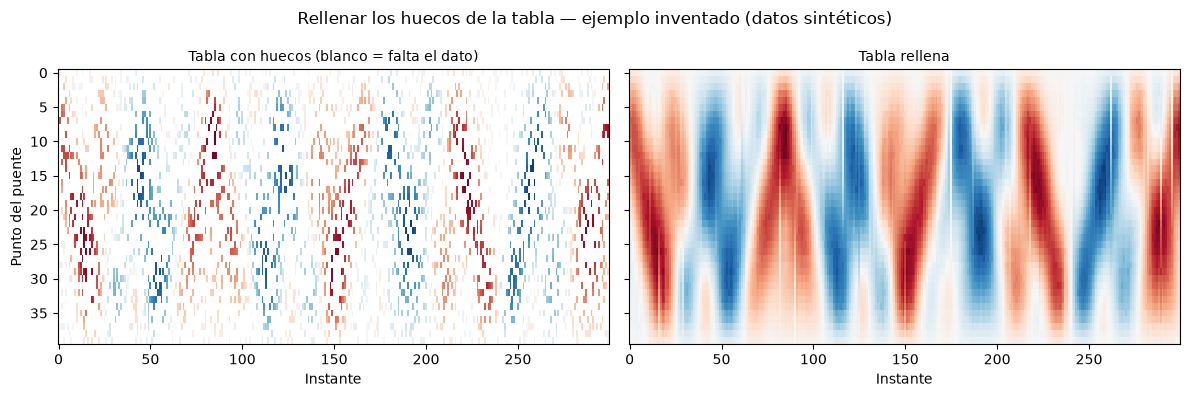

In [10]:
# A table with 80 % holes and the same table filled in (made-up example)
rng_si = np.random.default_rng(SEED + 14)
x_si = np.arange(1, 41) / 41
t_si = np.arange(300) / 100.0
Q_si = np.array([a * np.sin(2 * np.pi * f * t_si + p) for a, f, p in
                 zip([1.0, 0.5, 0.25], [1.44, 3.68, 4.66], [0.3, 1.1, 2.0])])
table_true = beam_modes(x_si, 3) @ Q_si
measured = rng_si.random(table_true.shape) < 0.2         # only 20 % of the cells are known
Z = np.zeros_like(table_true)
for _ in range(1000):                                     # fill, keep the main patterns, repeat
    U, s, Vt = np.linalg.svd(np.where(measured, table_true, Z), full_matrices=False)
    Z = (U * np.maximum(s - 0.3, 0)) @ Vt
filled = np.where(measured, table_true, Z)

vmax = np.abs(table_true).max()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, M, title in zip(axes, [np.where(measured, table_true, np.nan), filled],
                        ["Tabla con huecos (blanco = falta el dato)", "Tabla rellena"]):
    ax.imshow(M, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Instante")
    ax.grid(False)
axes[0].set_ylabel("Punto del puente")
fig.suptitle("Rellenar los huecos de la tabla — ejemplo inventado (datos sintéticos)")
fig.tight_layout()
plt.show()

**Figura 9.** Una tabla inventada con 80 % de huecos y la misma tabla rellena (ilustrativo, datos sintéticos): a la izquierda casi no se ve ningún patrón; a la derecha aparecen las franjas que forma la vibración del puente.

**Ventajas**

- Rellena muchos huecos.

**Desventajas**

- Con mucho ruido adivina peor.

**Artículos:** Mei et al. (2021).

**Entradas y salidas**

- **Entrada:** la tabla con huecos.
- **Salida:** la tabla completa.
- **Qué se obtiene o interpreta:** con ella se aplica la SVD ([2.2.4.2](#svd-completed-matrix)).

[↑ Volver al índice](#indice)

<a id="fdd-incomplete-matrix"></a>
##### 2.2.1.3 FDD on the incomplete matrix

*Versión técnica: [research_map_methods.ipynb, sección 2.2.1.3](research_map_methods.ipynb#fdd-incomplete-matrix)*

**Qué es**

- Es usar el FDD ([2.1.1.2](#fdd)) sin rellenar los huecos; los huecos se dejan en cero.
- Analogía: es como sacar el promedio de notas de un curso aunque algunos alumnos faltaron a un examen; con suficientes alumnos, el resultado casi no cambia.

**Ventajas**

- Se salta el paso de rellenar.

**Desventajas**

- Si hay demasiados huecos, empeora.

**Pregunta abierta**

> ¿Por qué funciona aunque falten tantos datos?

**Artículos:** Talebi-Kalaleh et al. (2025).

**Entradas y salidas**

- **Entrada:** la tabla con los huecos en cero.
- **Salida:** las notas y las formas del puente.
- **Qué se obtiene o interpreta:** cómo vibra el puente, sin tener que rellenar la tabla.

[↑ Volver al índice](#indice)

<a id="mode-shapes-signal-decomposition"></a>
#### 2.2.2 Signal decomposition

<a id="emd-hilbert"></a>
##### 2.2.2.1 EMD + Hilbert transform

*Versión técnica: [research_map_methods.ipynb, sección 2.2.2.1](research_map_methods.ipynb#emd-hilbert)*

**Qué es**

- La EMD es una forma de separar una vibración en capas, de la más rápida a la más lenta.
- Analogía: es como pelar una cebolla. Primero sale la capa de afuera, la vibración más rápida; luego la siguiente, y así hasta llegar al centro, que es la tendencia lenta.
- Cada capa se llama IMF. Es una vibración sencilla, que sube y baja de forma pareja.
- La transformada de Hilbert mira cada capa y dice, en cada momento, qué tan fuerte vibra y qué tan rápido.
- Analogía: es como tener en cada capa un medidor de volumen y un velocímetro.

**Para qué sirve**

- Para vibraciones que cambian mientras se miden.
- En un puente: para encontrar la capa que viene del puente y ver qué tan fuerte vibra en cada punto mientras el carro pasa.
- Analogía: es como seguir con el oído solo la guitarra en una canción, y notar cuándo suena más fuerte y cuándo más suave.

**Cómo funciona**

1. Se marcan los picos altos y los picos bajos de la vibración.
2. Se dibuja una línea que une los picos altos y otra que une los bajos.
3. Se saca el punto medio entre las dos líneas y se le resta a la vibración. Se repite hasta que lo que queda sube y baja de forma pareja. Esa es la primera capa.
4. Se le quita esa capa a la vibración original y se repite todo con lo que sobra, para sacar la siguiente capa.
5. Cuando lo que queda ya no sube y baja, se termina.
6. A cada capa se le pasa Hilbert, que dice su fuerza y su velocidad en cada momento.

Analogía de los pasos 1 a 3: es como un camino con curvas entre dos bordes. Se marca la línea del centro del camino y se mide cuánto se aleja el carro de ella.

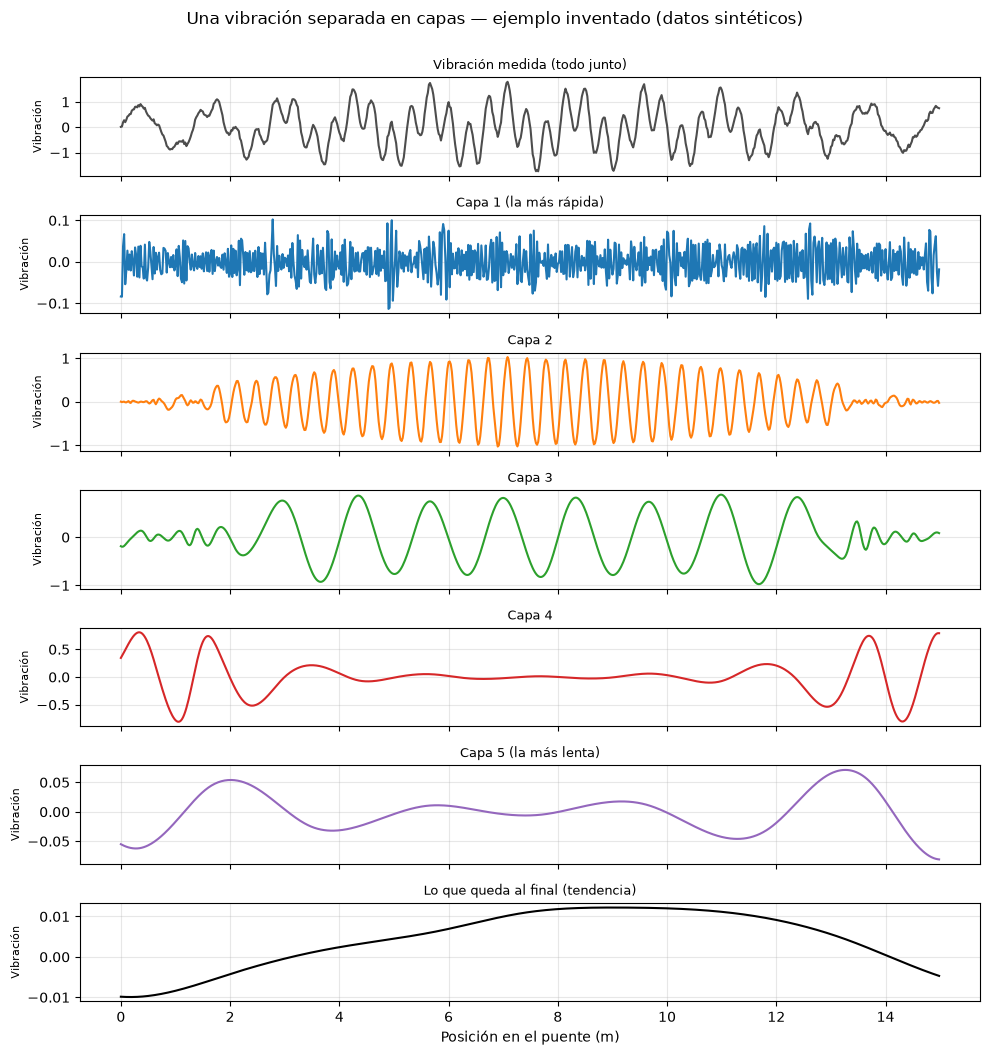

In [11]:
# Example: car crossing a 15 m bridge at 2 m/s (same as the technical notebook)
rng_emd = np.random.default_rng(SEED)   # own generator: keeps the other sections unchanged
L_b, v_b, f_b, fs_b = 15.0, 2.0, 5.65, 100.0   # length (m), speed (m/s), bridge note (Hz), samples per second
t_b = np.arange(0, L_b / v_b, 1 / fs_b)        # time, s
pos_b = v_b * t_b                              # car position on the bridge, m
shape_b = np.sin(np.pi * pos_b / L_b)          # how the bridge bends (mode 1)
x_b = (np.abs(shape_b) * np.cos(2 * np.pi * f_b * t_b)     # bridge vibration
       + 0.8 * np.sin(2 * np.pi * 1.5 * t_b)              # car vibration (made up, 1.5 Hz)
       + 0.05 * rng_emd.standard_normal(t_b.size))        # noise

emd_b = EMD()
emd_b.emd(x_b, t_b)
layers, rest = emd_b.get_imfs_and_residue()

fig, axes = plt.subplots(len(layers) + 2, 1, figsize=(10, 1.5 * (len(layers) + 2)), sharex=True)
axes[0].plot(pos_b, x_b, color="0.3")
axes[0].set_title("Vibración medida (todo junto)", fontsize=9)
for i, layer in enumerate(layers):
    axes[i + 1].plot(pos_b, layer, color=f"C{i}")
    label = "la más rápida" if i == 0 else ("la más lenta" if i == len(layers) - 1 else "")
    axes[i + 1].set_title(f"Capa {i + 1}" + (f" ({label})" if label else ""), fontsize=9)
axes[-1].plot(pos_b, rest, color="k")
axes[-1].set_title("Lo que queda al final (tendencia)", fontsize=9)
for ax in axes:
    ax.set_ylabel("Vibración", fontsize=8)
axes[-1].set_xlabel("Posición en el puente (m)")
fig.suptitle("Una vibración separada en capas — ejemplo inventado (datos sintéticos)", y=1.0)
fig.tight_layout()
plt.show()

**Figura 10.** Una vibración inventada separada en capas (ilustrativo): arriba está todo junto; debajo, las capas de la más rápida a la más lenta. La capa 1 es el ruido, la capa 2 es la vibración del puente y la capa 3 es la del carro. En las orillas las capas 3 y 4 se mezclan un poco: es el problema de las orillas que aparece en Desventajas.

**Cómo se usa para la forma modal**

- La forma modal es el dibujo de cómo se deforma el puente cuando vibra en una de sus notas.
- Se busca la capa que vibra a la "nota" del puente.
- Se mira qué tan fuerte vibra esa capa en cada punto del recorrido.
- Donde vibra fuerte, el puente se mueve mucho; donde casi no vibra, el puente casi no se mueve.
- Analogía: es como poner la mano en distintos puntos de una mesa que tiembla. Donde más tiembla, más se mueve la mesa.

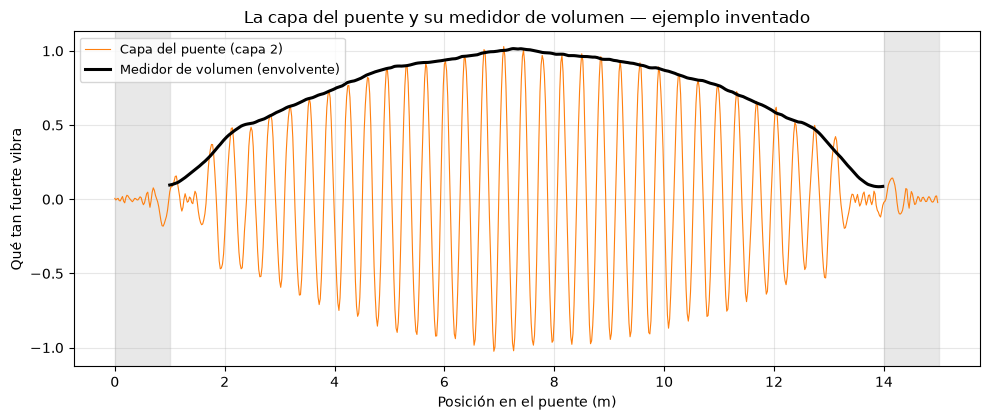

In [12]:
# Bridge layer and its "volume meter" (envelope) along the bridge
speeds = []
for layer in layers:
    phase = np.unwrap(np.angle(hilbert(layer)))
    speeds.append(np.median(np.gradient(phase) * fs_b / (2 * np.pi)))   # typical note of each layer, Hz
k_bridge = int(np.argmin(np.abs(np.array(speeds) - f_b)))           # layer closest to the bridge note
bridge_layer = layers[k_bridge]
volume = np.abs(hilbert(bridge_layer))                               # envelope from Hilbert
win = int(0.5 * fs_b)
volume_smooth = np.convolve(volume, np.ones(win) / win, mode="same") # smoothed (0.5 s moving average)
inner = slice(win, -win)                                             # ends are not reliable

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos_b, bridge_layer, color="C1", lw=0.8, label=f"Capa del puente (capa {k_bridge + 1})")
ax.plot(pos_b[inner], volume_smooth[inner], color="k", lw=2.2, label="Medidor de volumen (envolvente)")
for edge in [(0, pos_b[win]), (pos_b[-win], L_b)]:
    ax.axvspan(*edge, color="0.85", alpha=0.6)
ax.set_xlabel("Posición en el puente (m)")
ax.set_ylabel("Qué tan fuerte vibra")
ax.set_title("La capa del puente y su medidor de volumen — ejemplo inventado")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

**Figura 11.** La capa del puente con su medidor de volumen (ilustrativo, datos sintéticos): vibra poco en las orillas y fuerte en el centro, que es justo la forma en que se mueve este puente. Las franjas grises son el inicio y el final, donde el resultado no es confiable y se recorta.

**Ventajas**

- Las capas salen de la propia vibración; no hay que escoger una onda de prueba.
- Sirve para vibraciones que cambian.
- Dice la fuerza y la velocidad en cada instante.

**Desventajas**

- A veces dos vibraciones distintas quedan mezcladas en la misma capa.
- Analogía: es como cuando en una foto dos personas quedan pegadas y parecen una sola.
- En el inicio y el final de la señal las líneas se deforman, así que esas partes no son confiables.
- El ruido la afecta bastante.
- Hay que saber qué "nota" del puente buscar.

**Artículos:** Malekjafarian y OBrien (2017).

**Entradas y salidas**

- **Entrada:** la vibración medida y, para el puente, la posición del carro y la nota que se busca.
- **Salida:** las capas de la vibración y, para cada una, su fuerza y su velocidad en cada momento.
- **Qué se obtiene o interpreta:** qué capa viene del puente y qué tan fuerte vibra en cada punto, que es la base para dibujar cómo se deforma el puente.

[↑ Volver al índice](#indice)

<a id="fdd-mode-shapes"></a>
##### 2.2.2.2 FDD (Frequency Domain Decomposition)

Se explica en [2.1.1.2](#fdd). Aquí, además de las notas del puente, se usa la forma que sale en cada pico como forma modal.

<a id="wavelet-sswt"></a>
##### 2.2.2.3 Wavelet transform (SSWT)

*Versión técnica: [research_map_methods.ipynb, sección 2.2.2.3](research_map_methods.ipynb#wavelet-sswt)*

**Qué es**

- Es una herramienta que escucha una vibración y dice qué "notas" tiene y en qué momento suena cada una.
- Una "nota" es una frecuencia: cuántas veces por segundo se mueve algo de ida y vuelta.
- Analogía: es como una partitura. Fourier te dice qué notas hay en la canción completa; la wavelet además te dice en qué compás suena cada nota.

**Para qué sirve**

- Para vibraciones cortas o que cambian mientras se miden, como la de un carro que cruza un puente en pocos segundos.
- Con ella se puede ver cómo cambia la fuerza de una vibración del puente a medida que el carro avanza.
- Analogía: es como escuchar a alguien que pasa hablando frente a tu ventana. Solo lo oyes unos segundos, y su voz sube y baja mientras se acerca y se aleja.

**Cómo funciona**

1. Se toma una "onda de prueba": una pequeña vibración que empieza, oscila y se apaga, como el sonido de una campana.
2. Esa onda se hace más larga o más corta para probar cada nota (frecuencia).
3. Se va deslizando sobre la señal. Donde la señal vibra igual que la onda de prueba, "coinciden" y da un valor grande; donde no, da casi cero. Analogía: es como pasar un imán por la arena; solo se pegan las limaduras de hierro.
4. Con todos esos valores se arma un mapa de colores: el tiempo en un eje, las notas en el otro y el color indica qué tan fuerte suena cada nota en cada momento.

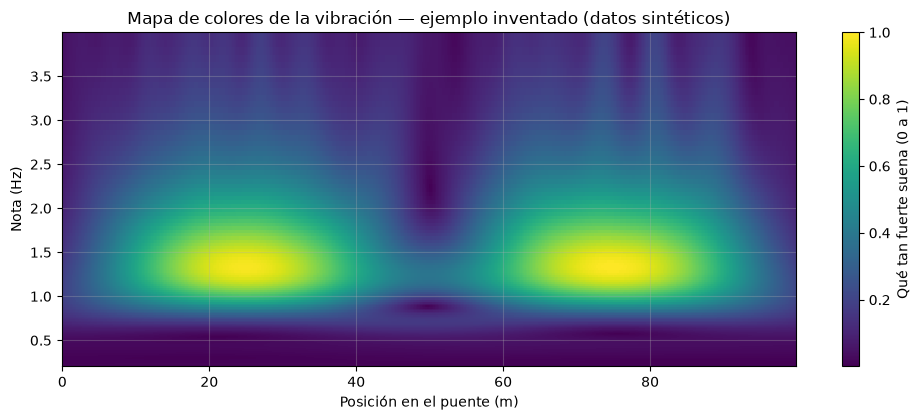

In [13]:
# Color map of the wavelet (CWT magnitude) versus car position
f_max = 4.0                                  # highest note shown, Hz
keep = freqs_cwt <= f_max
strength = np.abs(Wx[keep]) / np.abs(Wx).max()   # normalized: 1 = loudest

fig, ax = plt.subplots(figsize=(10, 4.3))
mesh = ax.pcolormesh(pos, freqs_cwt[keep], strength, shading="auto", cmap="viridis")
fig.colorbar(mesh, ax=ax, label="Qué tan fuerte suena (0 a 1)")
ax.set_xlabel("Posición en el puente (m)")
ax.set_ylabel("Nota (Hz)")
ax.set_title("Mapa de colores de la vibración — ejemplo inventado (datos sintéticos)")
fig.tight_layout()
plt.show()

**Figura 12.** Mapa de colores de una vibración inventada (ilustrativo): la nota de 1.3 Hz suena fuerte al inicio del puente, se apaga en el centro (50 m) y vuelve a sonar al final.

**Cómo se usa para la forma modal**

- La forma modal es el dibujo de cómo se deforma el puente cuando vibra en una de sus notas.
- El GPS dice dónde estaba el carro en cada momento, así que el tiempo se convierte en posición sobre el puente.
- Se mira solo la "nota" del puente que interesa y se ve qué tan fuerte suena en cada punto. Donde suena fuerte, el puente se mueve mucho; donde casi no suena, el puente casi no se mueve.
- Analogía: es como una cuerda de guitarra que vibra. Algunos puntos se mueven mucho y otros casi nada; si pasas el dedo por encima, sientes dónde vibra más.
- Juntando muchos viajes, se obtiene el dibujo de cómo se deforma el puente al vibrar.
- Analogía: es como tomar muchas fotos movidas de lo mismo y superponerlas; la forma se ve cada vez más clara.

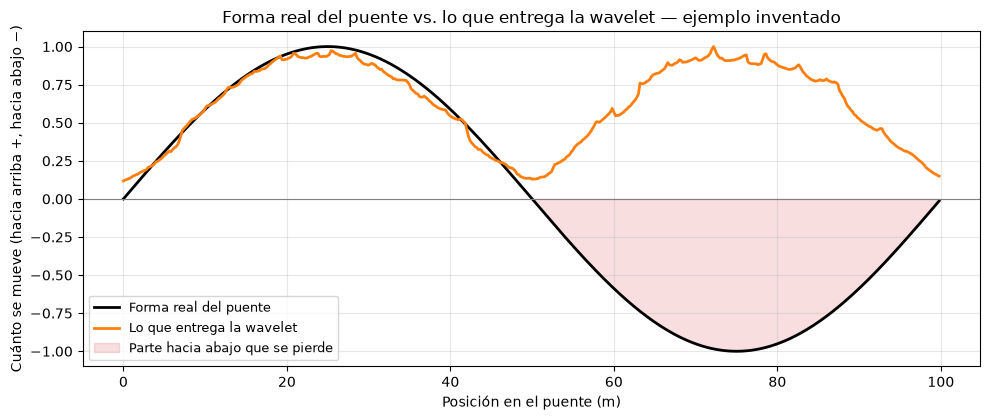

In [14]:
# Bridge shape from the wavelet: mean strength of the 1.3 Hz note at each position
band = np.abs(freqs_ssq - f_mode) <= 0.3     # only the bridge note (1.3 +/- 0.3 Hz)
shape_wavelet = np.abs(Tx[band]).mean(axis=0)
shape_wavelet /= shape_wavelet.max()         # normalized: 1 = largest movement

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos, shape_true, "k-", lw=2, label="Forma real del puente")
ax.plot(pos, shape_wavelet, color="C1", lw=2, label="Lo que entrega la wavelet")
ax.fill_between(pos, shape_true, 0, where=shape_true < 0, color="C3", alpha=0.15,
                label="Parte hacia abajo que se pierde")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("Posición en el puente (m)")
ax.set_ylabel("Cuánto se mueve (hacia arriba +, hacia abajo −)")
ax.set_title("Forma real del puente vs. lo que entrega la wavelet — ejemplo inventado")
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

**Figura 13.** Forma real del puente comparada con la que entrega la wavelet (ilustrativo, datos sintéticos): la mitad que en realidad baja (de 50 a 100 m) aparece hacia arriba, porque la wavelet solo dice cuánto se mueve cada punto, no hacia qué lado.

**Ventajas**

- Sirve para vibraciones cortas y que cambian.
- Dice a la vez qué nota suena y dónde.

**Desventajas**

- Hay que saber de antemano qué nota buscar.
- Dice qué tan fuerte se mueve cada punto, pero no hacia qué lado; el dibujo sale sin la parte "hacia abajo".
- Analogía: es como saber a qué distancia está alguien de la puerta, pero no si está a la izquierda o a la derecha.
- No separa la vibración del puente de la del carro.

**Artículos:** Dabbaghchian et al. (2025).

**Entradas y salidas**

- **Entrada:** la vibración que midió el teléfono, la ubicación del carro (GPS) y la nota del puente que se quiere buscar.
- **Salida:** un mapa de colores que dice qué notas suenan y en qué punto del puente.
- **Qué se obtiene o interpreta:** en qué partes del puente vibra más esa nota y, juntando muchos viajes, la forma en que se deforma el puente, sin saber hacia qué lado.

[↑ Volver al índice](#indice)

<a id="mode-shapes-bridge-components"></a>
#### 2.2.3 Bridge components

<a id="imf-exciter-frequency"></a>
##### 2.2.3.1 IMF near the exciter frequency

Se explica en EMD + Hilbert, [2.2.2.1](#emd-hilbert), "Cómo se usa para la forma modal".

<a id="peaks-first-singular-value-shapes"></a>
##### 2.2.3.2 Peaks of 1st singular value

Se explica dentro del FDD, [2.1.1.2](#fdd), paso 4.

<a id="band-known-frequency"></a>
##### 2.2.3.3 Band at the known frequency

*Versión técnica: [research_map_methods.ipynb, sección 2.2.3.3](research_map_methods.ipynb#band-known-frequency)*

**Qué es**

- Del mapa de colores de la wavelet ([2.2.2.3](#wavelet-sswt)), se queda solo con la franja de la "nota" del puente y mira qué tan fuerte suena en cada tramo.
- Analogía: en un ecualizador de música, mirar solo una barra y ver cómo sube y baja mientras avanzas.

**Para qué sirve**

- Para saber cuánto vibra el puente en esa nota en cada parte del recorrido.

**Cómo funciona**

1. Se escoge la nota del puente, que hay que conocer de antemano.
2. Se toma solo una franja muy delgada del mapa alrededor de esa nota.
3. Se recorre el puente por tramos de 24 m, avanzando de metro en metro, y en cada tramo se promedia qué tan fuerte suena la franja.

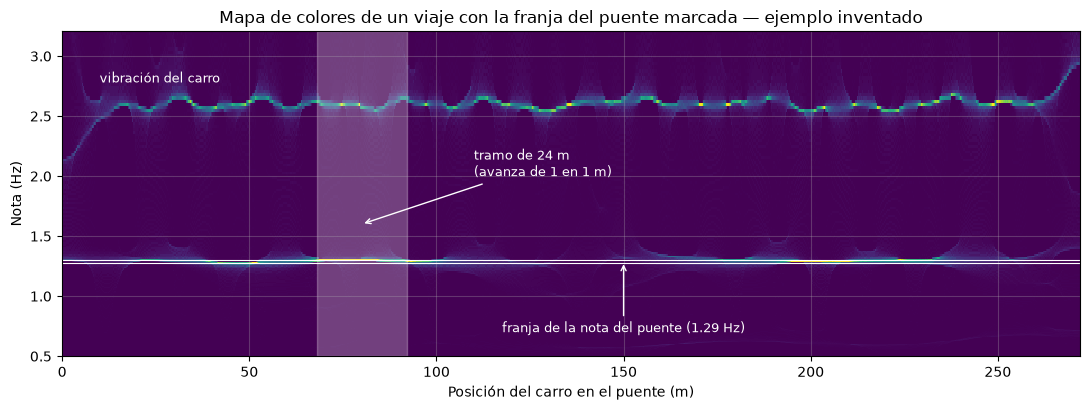

In [15]:
# Color map of one trip with the band of the bridge note marked (made-up example)
rng_bd = np.random.default_rng(SEED + 15)
L_bd, v_bd, fs_bd, f_m = 272.0, 15.0, 50.0, 1.29
t_bd = np.arange(0, L_bd / v_bd, 1 / fs_bd)
pos_bd = v_bd * t_bd
x_bd = (np.abs(np.sin(2 * np.pi * pos_bd / L_bd)) * np.cos(2 * np.pi * f_m * t_bd)
        + 0.6 * np.sin(2 * np.pi * 2.6 * t_bd) + 0.3 * rng_bd.standard_normal(t_bd.size))
Tx_bd, _, fr_bd, _ = ssq_cwt(x_bd, Wavelet(("morlet", {"mu": 6})), fs=fs_bd, nv=64, padtype="reflect")

fig, ax = plt.subplots(figsize=(11, 4.2))
keep = (fr_bd >= 0.5) & (fr_bd <= 3.2)
ax.pcolormesh(pos_bd, fr_bd[keep], (np.abs(Tx_bd) / np.abs(Tx_bd).max())[keep], shading="auto",
              cmap="viridis", vmax=0.6)
for fb in (f_m * 0.989, f_m * 1.011):                     # edges of the band
    ax.axhline(fb, color="w", lw=0.8)
ax.annotate("franja de la nota del puente (1.29 Hz)", (150, f_m), xytext=(150, 0.7), color="w", fontsize=9,
            ha="center", arrowprops=dict(arrowstyle="->", color="w"))
ax.axvspan(68, 92, color="w", alpha=0.25)
ax.annotate("tramo de 24 m\n(avanza de 1 en 1 m)", (80, 1.6), xytext=(110, 2.0), color="w", fontsize=9,
            arrowprops=dict(arrowstyle="->", color="w"))
ax.text(10, 2.78, "vibración del carro", color="w", fontsize=9)
ax.set_xlabel("Posición del carro en el puente (m)")
ax.set_ylabel("Nota (Hz)")
ax.set_title("Mapa de colores de un viaje con la franja del puente marcada — ejemplo inventado")
fig.tight_layout()
plt.show()

**Figura 14.** Mapa de colores de un viaje inventado (ilustrativo, datos sintéticos): la línea de abajo es la nota del puente y la de arriba es la vibración del carro. Solo se mira la franja delgada del puente, entre las dos líneas blancas, tramo por tramo; la parte clara es un tramo de 24 m.

**Ventajas**

- Es simple.

**Desventajas**

- Hay que saber la nota del puente.
- Cualquier ruido en esa misma nota se cuela.

**Artículos:** Dabbaghchian et al. (2025).

**Entradas y salidas**

- **Entrada:** el mapa de colores y la nota del puente.
- **Salida:** qué tan fuerte suena esa nota en cada tramo del puente.
- **Qué se obtiene o interpreta:** dónde vibra más el puente en ese viaje.

[↑ Volver al índice](#indice)

<a id="build-shape"></a>
#### 2.2.4 Build the shape along the bridge

<a id="rescaling-between-axles"></a>
##### 2.2.4.1 Rescaling between axles

*Versión técnica: [research_map_methods.ipynb, sección 2.2.4.1](research_map_methods.ipynb#rescaling-between-axles)*

**Qué es**

- Es armar la forma del puente comparando dos sensores que van a una distancia fija.
- Analogía: medir una escalera con dos personas separadas un paso. En cada momento comparan sus alturas y así, escalón por escalón, se arma toda la escalera.

**Para qué sirve**

- Lo que mide un sensor depende de la forma del puente y de qué tan fuerte vibra en ese momento, y eso cambia todo el tiempo.
- Al comparar los dos sensores en el mismo momento, lo que cambia se cancela y queda solo la forma.
- Analogía: si dos personas miden su estatura en una foto, el tamaño de la foto no importa; la comparación entre ellas sí.

**Cómo funciona**

1. Los dos sensores van separados 1 m.
2. En cada momento se divide lo que mide uno entre lo que mide el otro.
3. Se empieza en un punto y se avanza metro a metro, usando cada comparación para sacar el siguiente valor.

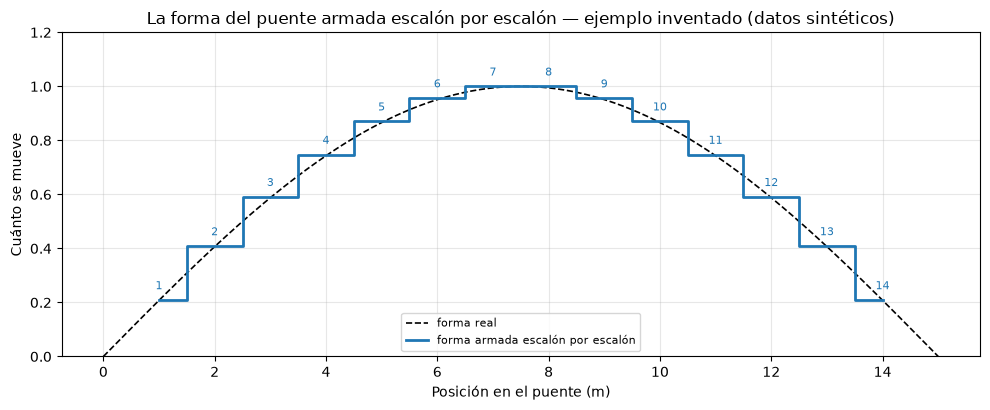

In [16]:
# The shape built step by step from the comparison of two sensors 1 m apart (made-up example)
t_rs = np.arange(0, 16 / 2.0, 1 / 100.0)
x6 = 2.0 * t_rs
x7 = x6 - 1.0
strength = 1 + 0.8 * np.sin(2 * np.pi * t_rs / 9)            # how strongly the bridge vibrates over time
shape_rs = lambda x: np.sin(np.pi * np.clip(x, 0, 15) / 15)
s1, s2 = strength * shape_rs(x6), strength * shape_rs(x7)
steps = [s2[np.argmin(np.abs(x7 - 1))], s1[np.argmin(np.abs(x7 - 1))]]
for j in range(2, 14):
    i = np.argmin(np.abs(x7 - j))
    steps.append(steps[-1] * s1[i] / s2[i])
steps = np.array(steps) / max(steps)
xs_rs = np.arange(1, 15)

fig, ax = plt.subplots(figsize=(10, 4.2))
xf = np.linspace(0, 15, 300)
ax.plot(xf, shape_rs(xf), "k--", lw=1.2, label="forma real")
ax.step(xs_rs, steps, where="mid", color="C0", lw=2, label="forma armada escalón por escalón")
for k, (xx, yy) in enumerate(zip(xs_rs, steps)):
    ax.text(xx, yy + 0.04, str(k + 1), ha="center", fontsize=8, color="C0")
ax.set_xlabel("Posición en el puente (m)")
ax.set_ylabel("Cuánto se mueve")
ax.set_ylim(0, 1.2)
ax.set_title("La forma del puente armada escalón por escalón — ejemplo inventado (datos sintéticos)")
ax.legend(loc="lower center", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 15.** La forma de un puente inventado armada escalón por escalón (ilustrativo, datos sintéticos): cada número es un paso; cada escalón sale del anterior comparando los dos sensores. Los escalones siguen a la forma real aunque la fuerza de la vibración cambió durante el viaje.

**Ventajas**

- No necesita sensores fijos en el puente.

**Desventajas**

- Los errores se van sumando de escalón en escalón.
- La forma sale sin signo: no dice qué partes suben y cuáles bajan.

**Artículos:** Malekjafarian y OBrien (2017).

**Entradas y salidas**

- **Entrada:** lo que miden los dos sensores a lo largo del puente.
- **Salida:** la forma del puente, punto por punto.
- **Qué se obtiene o interpreta:** cómo se deforma el puente a lo largo de todo su largo.

[↑ Volver al índice](#indice)

<a id="svd-completed-matrix"></a>
##### 2.2.4.2 SVD of the completed matrix

*Versión técnica: [research_map_methods.ipynb, sección 2.2.4.2](research_map_methods.ipynb#svd-completed-matrix)*

**Qué es**

- Es una forma de encontrar los patrones principales de una tabla de datos y cuánto pesa cada uno.
- Analogía: de cientos de fotos de una cuerda vibrando, encontrar las pocas formas básicas con las que se pueden armar todas.

**Para qué sirve**

- Para sacar las formas en que se mueve el puente de una tabla de puntos contra tiempo.
- Para quitar ruido.
- Analogía: es como quedarse con las pocas melodías principales de una grabación y dejar fuera el siseo de fondo.

**Cómo funciona**

1. Se arma una tabla con una fila por punto del puente y una columna por instante.
2. La SVD la separa en formas básicas, ordenadas de la más importante a la menos importante.
3. Las primeras formas son las formas del puente. Las últimas son ruido.

Analogía: es como ordenar los ingredientes de una receta por cantidad. Los primeros dan el sabor; los últimos son una pizca que casi no se nota.

**En el puente**

- Primero se rellenan los huecos de la tabla (*soft imputing*, [2.2.1.2](#soft-imputing): una forma de adivinar los datos que faltan a partir de los que sí hay).
- Luego se aplica la SVD.

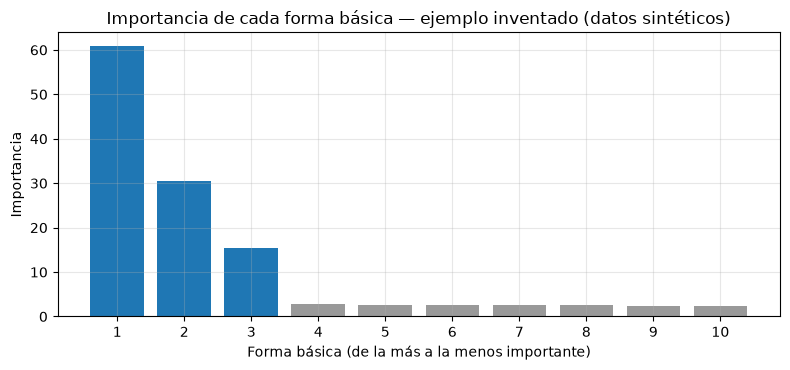

In [17]:
# Made-up table: 10 points x 677 instants of a bridge with 3 shapes, plus noise
rng_svd = np.random.default_rng(SEED + 4)
x_d = np.arange(1, 11) / 11                     # 10 points along the bridge
shapes_d = beam_modes(x_d, 3)                   # true shapes
Q_d = modal_response([1.44, 3.68, 4.66], 0.02, 100.0, 677, rng_svd) * np.array([[1.0], [0.5], [0.25]])
table = shapes_d @ Q_d + 0.1 * rng_svd.standard_normal((10, 677))
U_d, s_d, _ = np.linalg.svd(table, full_matrices=False)   # basic shapes and their importance

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(np.arange(1, 11), s_d, color=["C0"] * 3 + ["0.6"] * 7)
ax.set_xticks(np.arange(1, 11))
ax.set_xlabel("Forma básica (de la más a la menos importante)")
ax.set_ylabel("Importancia")
ax.set_title("Importancia de cada forma básica — ejemplo inventado (datos sintéticos)")
fig.tight_layout()
plt.show()

**Figura 16.** Importancia de cada forma básica de una tabla inventada (ilustrativo, datos sintéticos): tres formas son grandes, en azul, y son las formas del puente. Las otras siete son pequeñas y parecidas entre sí: son el ruido.

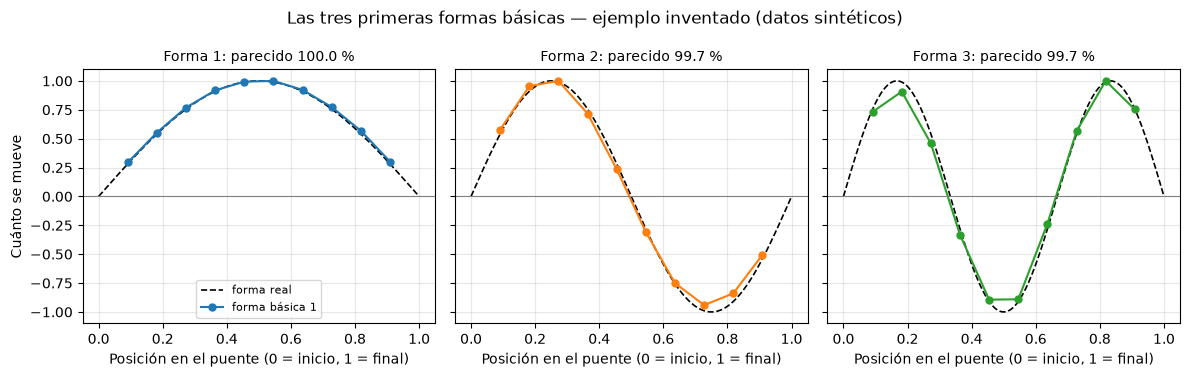

In [18]:
# The first three basic shapes next to the real shapes
x_fine = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for k, ax in enumerate(axes):
    found = U_d[:, k] / np.max(np.abs(U_d[:, k]))
    found = found if np.dot(found, shapes_d[:, k]) >= 0 else -found
    ax.plot(x_fine, np.sin((k + 1) * np.pi * x_fine), "k--", lw=1.2, label="forma real")
    ax.plot(x_d, found, "o-", color=f"C{k}", ms=5, label=f"forma básica {k + 1}")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(f"Forma {k + 1}: parecido {100 * mac(shapes_d[:, k], U_d[:, k]):.1f} %", fontsize=10)
    ax.set_xlabel("Posición en el puente (0 = inicio, 1 = final)")
axes[0].set_ylabel("Cuánto se mueve")
axes[0].legend(loc="lower center", fontsize=8)
fig.suptitle("Las tres primeras formas básicas — ejemplo inventado (datos sintéticos)")
fig.tight_layout()
plt.show()

**Figura 17.** Las tres primeras formas básicas junto a las formas reales del puente inventado (ilustrativo, datos sintéticos): coinciden casi por completo. Las formas básicas salen sin tamaño ni sentido, así que se escalan y se voltean para compararlas.

**Ventajas**

- Funciona con cualquier tabla.
- Separa lo importante del ruido.

**Desventajas**

- La tabla tiene que estar completa.
- Si dos formas tienen fuerza parecida, se pueden mezclar.
- Analogía: es como dos voces del mismo volumen en una grabación; cuesta saber qué parte es de cada una.

**Artículos:** Mei et al. (2021); también se usa dentro del FDD.

**Entradas y salidas**

- **Entrada:** la tabla completa de puntos contra tiempo.
- **Salida:** las formas básicas y su importancia.
- **Qué se obtiene o interpreta:** las primeras formas son las formas modales del puente.

[↑ Volver al índice](#indice)

<a id="singular-vectors-peaks"></a>
##### 2.2.4.3 Singular vectors at peaks

Se explica dentro del FDD, [2.1.1.2](#fdd), paso 5.

<a id="average-many-trips"></a>
##### 2.2.4.4 Average of many trips

*Versión técnica: [research_map_methods.ipynb, sección 2.2.4.4](research_map_methods.ipynb#average-many-trips)*

**Qué es**

- Es juntar muchos viajes y promediarlos para que aparezca la forma del puente.
- Analogía: una foto con mucho ruido no se ve. Si superpones cientos de fotos del mismo lugar, el ruido se borra y se ve la imagen.

**Para qué sirve**

- En un solo viaje con el teléfono, la vibración del puente casi no se distingue del ruido.

**Cómo funciona**

1. Cada viaje da una curva de qué tan fuerte vibra el puente en cada tramo ([2.2.3.3](#band-known-frequency)).
2. Se promedian todas las curvas, tramo por tramo.
3. El error de cada viaje es distinto y se cancela; la forma, que es la misma en todos, queda.

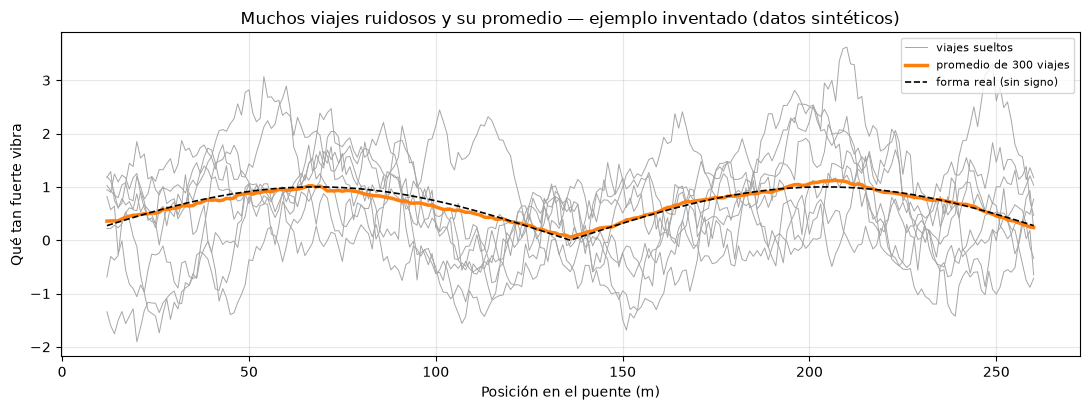

In [19]:
# Many noisy trips and their clean average (made-up example)
rng_av = np.random.default_rng(SEED + 17)
xj = np.arange(12.0, 261.0, 1.0)
shape_av = np.abs(np.sin(2 * np.pi * xj / 272.0))
def noisy_trip():
    e = np.convolve(rng_av.standard_normal(xj.size + 23), np.ones(24) / 24, mode="valid")
    return rng_av.uniform(0.5, 1.5) * shape_av + 0.8 * e / e.std()
trips = np.array([noisy_trip() for _ in range(300)])

fig, ax = plt.subplots(figsize=(11, 4.2))
for k in range(8):
    ax.plot(xj, trips[k], color="0.65", lw=0.7, label="viajes sueltos" if k == 0 else None)
ax.plot(xj, trips.mean(axis=0), color="C1", lw=2.5, label="promedio de 300 viajes")
ax.plot(xj, shape_av, "k--", lw=1.2, label="forma real (sin signo)")
ax.set_xlabel("Posición en el puente (m)")
ax.set_ylabel("Qué tan fuerte vibra")
ax.set_title("Muchos viajes ruidosos y su promedio — ejemplo inventado (datos sintéticos)")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 18.** Ocho viajes inventados (gris) y el promedio de 300 viajes (naranja) (ilustrativo, datos sintéticos): cada viaje suelto es casi puro ruido; el promedio es una curva limpia que sigue la forma real del puente.

**Ventajas**

- No hace falta que los viajes sean al mismo tiempo.

**Desventajas**

- Se necesitan muchos viajes (al menos 200).
- Los viajes malos empeoran el resultado.

**Artículos:** Dabbaghchian et al. (2025).

**Entradas y salidas**

- **Entrada:** muchos viajes sobre el mismo puente.
- **Salida:** la forma del puente, sin signo.
- **Qué se obtiene o interpreta:** cómo se deforma el puente, sin saber qué partes suben y cuáles bajan.

[↑ Volver al índice](#indice)